In [22]:
from pathlib import Path
import os, json, re, time, base64, mimetypes, hashlib, random
import pandas as pd
import numpy as np
from IPython.display import display
import Levenshtein

ROOT = Path.cwd()
if not (ROOT / "results" / "cord_vlm").exists() and (ROOT.parent / "results" / "cord_vlm").exists():
    ROOT = ROOT.parent
assert (ROOT / "results" / "cord_vlm").exists(), "Open this notebook from the project or notebooks directory."
OUT = ROOT / "results" / "cord_ablation_pilot"
OUT.mkdir(parents=True, exist_ok=True)
FIELDS = ["item_name", "item_price", "sub_total", "tax", "total"]
SOURCE = ROOT / "results/cord_vlm/qwen_vlm_7b_cord_test_filtered.json"
source_records = json.loads(SOURCE.read_text(encoding="utf-8"))
source_ids = sorted({str(r["source_image"]) for r in source_records}, key=lambda x:int(Path(x).stem))
print("Project:", ROOT)
print("Saved comparison IDs:", len(source_ids))
print("Output directory:", OUT)

Project: /root/lorex-ocr-llm-experiments
Saved comparison IDs: 83
Output directory: /root/lorex-ocr-llm-experiments/results/cord_ablation_pilot


In [23]:
MODEL_NAME = "Qwen/Qwen2.5-VL-72B-Instruct:fastest"
PILOT_SIZE = 10
SEED = 20261021
MAX_TOKENS = 500
MAX_RETRIES = 2
RUN_INFERENCE = True  # change to True only when ready for API calls
IMAGE_DIR = None       # e.g. ROOT / "data" / "cord" / "test_images"

rng = random.Random(SEED)
pilot_ids = sorted(rng.sample(source_ids, min(PILOT_SIZE, len(source_ids))), key=lambda x:int(Path(x).stem))
print("Fixed pilot IDs:", pilot_ids)

def discover_image_dir():
    candidate_dirs = []
    for p in [ROOT / "data", ROOT / "datasets", ROOT / "images", ROOT / "cord", ROOT / "data" / "cord"]:
        if p.exists():
            candidate_dirs.append(p)
    for base in candidate_dirs:
        for p in base.rglob(pilot_ids[0]):
            if p.is_file():
                d = p.parent
                if all((d / name).is_file() for name in pilot_ids):
                    return d
    return None

if IMAGE_DIR is None:
    IMAGE_DIR = discover_image_dir()
if IMAGE_DIR is not None:
    IMAGE_DIR = Path(IMAGE_DIR)
print("IMAGE_DIR:", IMAGE_DIR)
if IMAGE_DIR is None:
    print("Set IMAGE_DIR manually in this cell before enabling inference.")

Fixed pilot IDs: ['1.png', '33.png', '48.png', '56.png', '57.png', '61.png', '72.png', '84.png', '90.png', '93.png']
IMAGE_DIR: /root/lorex-ocr-llm-experiments/data/cord_test/images


In [24]:
BASELINE_PROMPT = """Extract structured fields from this receipt image.

Return ONLY valid JSON with exactly these keys:
{
  "item_name": null,
  "item_price": null,
  "sub_total": null,
  "tax": null,
  "total": null
}

Rules:
- Copy values exactly as written in the image.
- Do not normalize commas, dots, spaces, or currency symbols.
- item_name = the first main purchased item, not store name, not payment method, not summary line.
- item_price = the price associated with item_name, not subtotal, tax, cash, or change.
- sub_total = value near keywords like SUBTOTAL, SUB TOTAL, or Sub Total.
- tax = value near keywords like TAX, PB1, or service tax.
- total = final payable amount near keywords like TOTAL, GRAND TOTAL, or Total.
- Do NOT use CASH, CHANGE, CARD PAYMENT, CREDIT CARD, or DISCOUNT as total.
- If multiple totals appear, choose the final payable amount.
- If unsure, output null.
- Return JSON only.""".strip()

SCHEMA = """{
  "item_name": null,
  "item_price": null,
  "sub_total": null,
  "tax": null,
  "total": null
}"""

RULES = """- item_name = the first main purchased item, not store name, not payment method, not summary line.
- item_price = the price associated with item_name, not subtotal, tax, cash, or change.
- sub_total = value near keywords like SUBTOTAL, SUB TOTAL, or Sub Total.
- tax = value near keywords like TAX, PB1, or service tax.
- total = final payable amount near keywords like TOTAL, GRAND TOTAL, or Total.
- Do NOT use CASH, CHANGE, CARD PAYMENT, CREDIT CARD, or DISCOUNT as total.
- If multiple totals appear, choose the final payable amount."""

FORMATTING = """- Copy values exactly as written in the image.
- Do not normalize commas, dots, spaces, or currency symbols."""

def remove_lines(prompt, lines):
    for line in lines.splitlines():
        prompt = prompt.replace(line + "\n", "").replace("\n" + line, "")
    return prompt.strip()

PROMPTS = {
    "A0_baseline": BASELINE_PROMPT,
    "A1_no_field_rules": remove_lines(BASELINE_PROMPT, RULES),
    "A2_no_explicit_schema": BASELINE_PROMPT.replace(
        "Return ONLY valid JSON with exactly these keys:\n" + SCHEMA,
        "Return ONLY valid JSON containing the fields item_name, item_price, sub_total, tax, total."
    ),
    "A3_no_format_rules": remove_lines(BASELINE_PROMPT, FORMATTING),
}
assert len(PROMPTS) == 4 and len(set(PROMPTS.values())) == 4
for name, prompt in PROMPTS.items():
    print(f"{name}: {len(prompt)} characters, SHA256={hashlib.sha256(prompt.encode()).hexdigest()[:12]}")
display(pd.DataFrame([{"variant": k, "prompt": v} for k,v in PROMPTS.items()]))

A0_baseline: 899 characters, SHA256=f7dc8d64db66
A1_no_field_rules: 361 characters, SHA256=51a17e9f5c2a
A2_no_explicit_schema: 843 characters, SHA256=9e2c436eedf2
A3_no_format_rules: 790 characters, SHA256=d49c1a6ac793


,variant,prompt
0,A0_baseline,Extract structured fields from this receipt im...
1,A1_no_field_rules,Extract structured fields from this receipt im...
2,A2_no_explicit_schema,Extract structured fields from this receipt im...
3,A3_no_format_rules,Extract structured fields from this receipt im...


In [25]:
try:
    from datasets import load_dataset
except ImportError as e:
    raise ImportError("Install dependencies in your venv: pip install datasets huggingface_hub python-dotenv rapidfuzz python-Levenshtein pandas") from e
from rapidfuzz import fuzz
import Levenshtein

ds = load_dataset("naver-clova-ix/cord-v2", split="test")
def gt_from_sample(sample):
    gt = json.loads(sample["ground_truth"])
    gp = gt.get("gt_parse", {})
    menu = gp.get("menu", {})
    if isinstance(menu, list):
        menu = menu[0] if menu and isinstance(menu[0], dict) else {}
    if not isinstance(menu, dict): menu = {}
    sub = gp.get("sub_total", {})
    total = gp.get("total", {})
    if not isinstance(sub, dict): sub = {}
    if not isinstance(total, dict): total = {}
    return {
        "source_image": f'{gt["meta"]["image_id"]}.png',
        "item_name": menu.get("nm"),
        "item_price": menu.get("price"),
        "sub_total": sub.get("subtotal_price"),
        "tax": sub.get("tax_price"),
        "total": total.get("total_price")
    }
gt_map = {r["source_image"]: r for r in map(gt_from_sample, ds)}
assert all(x in gt_map for x in pilot_ids), "Pilot IDs not found in CORD ground truth."
print("Ground-truth receipts:", len(gt_map))

def norm_text(x):
    if x is None: return ""
    return re.sub(r"\s+", " ", str(x).strip().lower().replace(",", ".")).strip()

def score_field(pred, gold):
    p, g = norm_text(pred), norm_text(gold)
    em = int(bool(g) and p == g)
    fuzzy = fuzz.ratio(p, g) / 100 if g else 0.0
    lev = 1 - Levenshtein.distance(p, g) / max(len(g), 1) if g else 0.0
    if g and p == g: tp, fp, fn = 1,0,0
    elif g and p: tp, fp, fn = 0,1,1
    elif g: tp, fp, fn = 0,0,1
    elif p: tp, fp, fn = 0,1,0
    else: tp, fp, fn = 0,0,0
    return em, fuzzy, lev, tp, fp, fn

'_ssl.c:983: The handshake operation timed out' thrown while requesting HEAD https://huggingface.co/datasets/naver-clova-ix/cord-v2/resolve/7f0115a4b758a71d6473b8d085751692da2fef98/cord-v2.py
Retrying in 1s [Retry 1/5].
'_ssl.c:983: The handshake operation timed out' thrown while requesting HEAD https://huggingface.co/datasets/naver-clova-ix/cord-v2/resolve/7f0115a4b758a71d6473b8d085751692da2fef98/cord-v2.py
Retrying in 2s [Retry 2/5].
'_ssl.c:983: The handshake operation timed out' thrown while requesting HEAD https://huggingface.co/datasets/naver-clova-ix/cord-v2/resolve/7f0115a4b758a71d6473b8d085751692da2fef98/cord-v2.py
Retrying in 4s [Retry 3/5].


Ground-truth receipts: 100


In [26]:
from dotenv import load_dotenv
load_dotenv(ROOT / ".env")
RAW_PATH = OUT / "raw_responses.jsonl"
CONFIG_PATH = OUT / "config.json"

config = {
    "model": MODEL_NAME, "pilot_ids": pilot_ids, "seed": SEED,
    "max_tokens": MAX_TOKENS, "prompts": PROMPTS,
    "source_file": str(SOURCE.relative_to(ROOT)),
    "ground_truth_dataset": "naver-clova-ix/cord-v2:test",
    "evaluation_policy": "original_CORD_2026",
}
if CONFIG_PATH.exists():
    previous = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
    if previous != config:
        raise RuntimeError("Saved pilot config differs from current config. Use a new OUT directory to avoid mixing runs.")
else:
    CONFIG_PATH.write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")

def read_raw():
    if not RAW_PATH.exists(): return []
    return [json.loads(line) for line in RAW_PATH.read_text(encoding="utf-8").splitlines() if line.strip()]

def data_url(path):
    mime = mimetypes.guess_type(str(path))[0] or "image/png"
    return "data:" + mime + ";base64," + base64.b64encode(path.read_bytes()).decode("ascii")

if RUN_INFERENCE:
    if IMAGE_DIR is None or not all((IMAGE_DIR / x).is_file() for x in pilot_ids):
        raise FileNotFoundError("Set IMAGE_DIR to a folder containing all ten selected receipt images.")
    token = os.getenv("HF_TOKEN")
    if not token: raise RuntimeError("HF_TOKEN not found. Put it in your local .env (do not share the token).")
    from huggingface_hub import InferenceClient
    client = InferenceClient(api_key=token)
    done = {(r["variant"], r["source_image"]) for r in read_raw()}
    for variant, prompt in PROMPTS.items():
        for name in pilot_ids:
            if (variant, name) in done:
                continue
            response, error, elapsed = None, None, None
            for attempt in range(MAX_RETRIES + 1):
                start = time.monotonic()
                try:
                    completion = client.chat.completions.create(
                        model=MODEL_NAME,
                        messages=[{"role": "user", "content": [
                            {"type": "text", "text": prompt},
                            {"type": "image_url", "image_url": {"url": data_url(IMAGE_DIR / name)}}
                        ]}],
                        max_tokens=MAX_TOKENS,
                        temperature=0,
                    )
                    response = completion.choices[0].message.content
                    elapsed = round(time.monotonic() - start, 3)
                    error = None
                    break
                except Exception as e:
                    error = f"{type(e).__name__}: {str(e)[:350]}"
                    elapsed = round(time.monotonic() - start, 3)
                    if attempt < MAX_RETRIES: time.sleep(min(2 ** attempt, 8))
            rec = {"variant": variant, "source_image": name, "model": MODEL_NAME,
                   "raw_output": response, "error": error, "elapsed_s": elapsed}
            with RAW_PATH.open("a", encoding="utf-8") as f:
                f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            print(variant, name, "OK" if error is None else f"ERROR: {error}")
else:
    print("RUN_INFERENCE=False. No model calls made.")
print("Saved raw records:", len(read_raw()), "of", len(PROMPTS) * len(pilot_ids))

Saved raw records: 40 of 40


In [27]:
def strip_code_fences(text):
    text = (text or "").strip()
    if text.startswith("```"):
        text = re.sub(r"^```(?:json)?\s*", "", text, flags=re.I)
        text = re.sub(r"\s*```$", "", text)
    return text.strip()

def parse_raw(text, strip_fences=True):
    if text is None: return None, "missing_response"
    try:
        obj = json.loads(strip_code_fences(text) if strip_fences else text.strip())
        if not isinstance(obj, dict):
            return None, "non_object_json"
        return {f: obj.get(f) for f in FIELDS}, None
    except Exception as e:
        return None, f"parse_error:{type(e).__name__}"

raw = read_raw()
rows = []
for rec in raw:
    for parser_name, strip in [("with_fence_stripping", True), ("strict_json_only", False)]:
        parsed, parse_error = parse_raw(rec.get("raw_output"), strip)
        row = {k:rec.get(k) for k in ["variant", "source_image", "model", "error", "elapsed_s"]}
        row.update({"parser":parser_name, "parse_error":parse_error, "parse_ok":parsed is not None})
        row.update(parsed if parsed is not None else {f:None for f in FIELDS})
        rows.append(row)
predictions = pd.DataFrame(rows)
if len(predictions):
    display(predictions.groupby(["variant","parser"], as_index=False).agg(
        n=("source_image","size"), parsed_ok=("parse_ok","sum")
    ))
    predictions.to_csv(OUT / "parsed_predictions.csv", index=False)
else:
    print("No raw outputs yet. Enable inference above to generate them.")

,variant,parser,n,parsed_ok
0,A0_baseline,strict_json_only,10,0
1,A0_baseline,with_fence_stripping,10,6
2,A1_no_field_rules,strict_json_only,10,5
3,A1_no_field_rules,with_fence_stripping,10,10
4,A2_no_explicit_schema,strict_json_only,10,0
5,A2_no_explicit_schema,with_fence_stripping,10,10
6,A3_no_format_rules,strict_json_only,10,0
7,A3_no_format_rules,with_fence_stripping,10,10


In [28]:
def evaluate_predictions(frame):
    records=[]
    for (variant, parser), group in frame.groupby(["variant","parser"]):
        mapped = {r["source_image"]: r for r in group.to_dict("records")}
        if len(mapped) != len(pilot_ids) or any(x not in mapped for x in pilot_ids):
            print("Skipping incomplete run:", variant, parser, len(mapped), "/", len(pilot_ids))
            continue
        for field in FIELDS:
            vals = [score_field(mapped[sid].get(field), gt_map[sid].get(field)) for sid in pilot_ids]
            a = np.asarray(vals, dtype=float)
            tp, fp, fn = a[:,3:].sum(axis=0)
            precision = tp/(tp+fp) if tp+fp else 0.
            recall = tp/(tp+fn) if tp+fn else 0.
            f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.
            records.append({
                "variant":variant,"parser":parser,"field":field,"n":len(pilot_ids),
                "exact_match":a[:,0].mean()*100,
                "fuzzy_score":a[:,1].mean()*100,
                "lev_similarity":a[:,2].mean()*100,
                "precision":precision*100,"recall":recall*100,"f1_score":f1*100,
                "tp":int(tp),"fp":int(fp),"fn":int(fn)
            })
    return pd.DataFrame(records)

metrics = evaluate_predictions(predictions) if len(predictions) else pd.DataFrame()
if len(metrics):
    metrics.to_csv(OUT / "per_field_metrics.csv", index=False)
    summary = metrics.groupby(["variant","parser"],as_index=False)[
        ["exact_match","fuzzy_score","lev_similarity","precision","recall","f1_score"]
    ].mean()
    summary.to_csv(OUT / "macro_summary.csv", index=False)
    display(summary.round(2))
    display(metrics[metrics["parser"]=="with_fence_stripping"].round(2))
else:
    print("No complete variant runs to evaluate yet.")

,variant,parser,exact_match,fuzzy_score,lev_similarity,precision,recall,f1_score
0,A0_baseline,strict_json_only,0.0,2.62,1.61,0.0,0.00,0.00
1,A0_baseline,with_fence_stripping,52.0,53.10,52.67,52.0,59.04,55.05
2,A1_no_field_rules,strict_json_only,34.0,38.09,37.27,34.0,37.25,35.44
3,A1_no_field_rules,with_fence_stripping,84.0,86.96,86.58,84.0,95.14,88.84
4,A2_no_explicit_schema,strict_json_only,0.0,2.62,1.61,0.0,0.00,0.00
5,A2_no_explicit_schema,with_fence_stripping,88.0,88.00,88.00,88.0,100.00,93.20
6,A3_no_format_rules,strict_json_only,0.0,2.62,1.61,0.0,0.00,0.00
7,A3_no_format_rules,with_fence_stripping,78.0,86.04,85.51,78.0,88.42,82.52


,variant,parser,field,n,exact_match,fuzzy_score,lev_similarity,precision,recall,f1_score,tp,fp,fn
5,A0_baseline,with_fence_stripping,item_name,10,60.0,65.48,63.33,60.0,60.00,60.00,6,4,4
6,A0_baseline,with_fence_stripping,item_price,10,60.0,60.00,60.00,60.0,60.00,60.00,6,4,4
7,A0_baseline,with_fence_stripping,sub_total,10,50.0,50.00,50.00,50.0,62.50,55.56,5,5,3
8,A0_baseline,with_fence_stripping,tax,10,40.0,40.00,40.00,40.0,57.14,47.06,4,6,3
9,A0_baseline,with_fence_stripping,total,10,50.0,50.00,50.00,50.0,55.56,52.63,5,5,4
15,A1_no_field_rules,with_fence_stripping,item_name,10,90.0,99.78,99.55,90.0,90.00,90.00,9,1,1
16,A1_no_field_rules,with_fence_stripping,item_price,10,100.0,100.00,100.00,100.0,100.00,100.00,10,0,0
17,A1_no_field_rules,with_fence_stripping,sub_total,10,80.0,80.00,80.00,80.0,100.00,88.89,8,2,0
18,A1_no_field_rules,with_fence_stripping,tax,10,60.0,65.00,63.33,60.0,85.71,70.59,6,4,1
19,A1_no_field_rules,with_fence_stripping,total,10,90.0,90.00,90.00,90.0,100.00,94.74,9,1,0


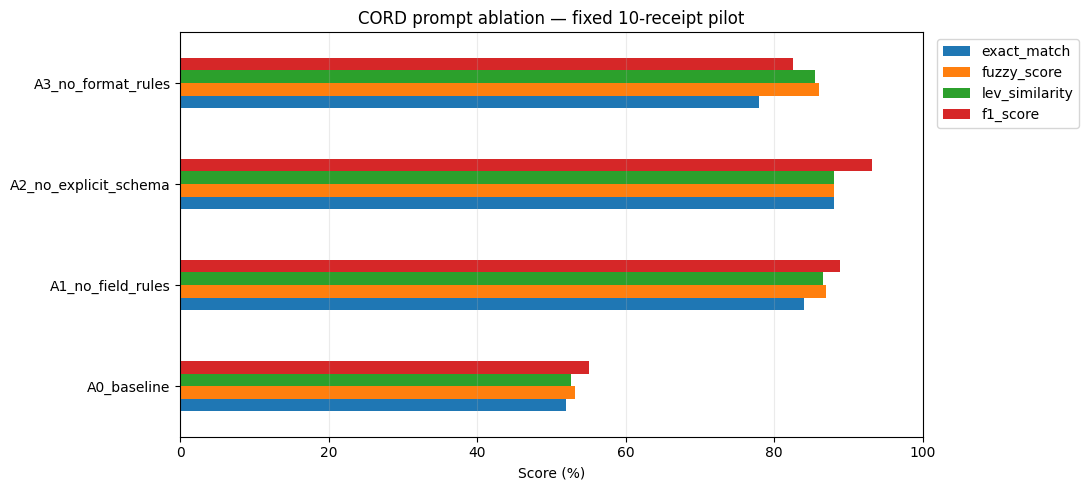

parser,strict_json_only,with_fence_stripping
variant,,
A0_baseline,0.00,55.05
A1_no_field_rules,35.44,88.84
A2_no_explicit_schema,0.00,93.20
A3_no_format_rules,0.00,82.52


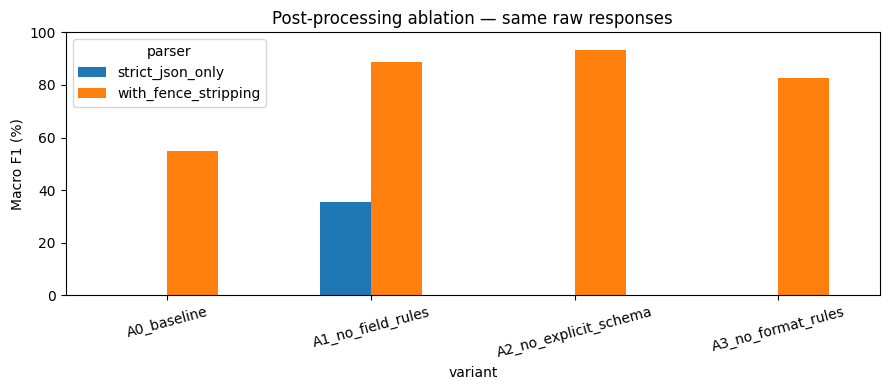

In [29]:
import matplotlib.pyplot as plt
if len(metrics):
    fig_dir = OUT / "figures"
    fig_dir.mkdir(exist_ok=True)
    main = summary[summary["parser"]=="with_fence_stripping"].set_index("variant")
    if len(main):
        ax = main[["exact_match","fuzzy_score","lev_similarity","f1_score"]].plot(
            kind="barh", figsize=(11,5), xlim=(0,100))
        ax.set_xlabel("Score (%)")
        ax.set_ylabel("")
        ax.set_title(f"CORD prompt ablation — fixed {len(pilot_ids)}-receipt pilot")
        ax.grid(axis="x", alpha=.25)
        ax.legend(loc="upper left", bbox_to_anchor=(1.01,1))
        plt.tight_layout()
        plt.savefig(fig_dir/"prompt_ablation_overall.png", dpi=220, bbox_inches="tight")
        plt.savefig(fig_dir/"prompt_ablation_overall.pdf", bbox_inches="tight")
        plt.show()
    parser_comparison = summary.pivot(index="variant", columns="parser", values="f1_score")
    display(parser_comparison.round(2))
    ax = parser_comparison.plot(kind="bar", figsize=(9,4), ylim=(0,100))
    ax.set_ylabel("Macro F1 (%)")
    ax.set_title("Post-processing ablation — same raw responses")
    ax.tick_params(axis="x", rotation=15)
    plt.tight_layout()
    plt.savefig(fig_dir/"parser_ablation_f1.png", dpi=220, bbox_inches="tight")
    plt.savefig(fig_dir/"parser_ablation_f1.pdf", bbox_inches="tight")
    plt.show()
else:
    print("Run inference and evaluation cells first.")

## 8. Audit and interpretation checklist

Before reporting an ablation to Reviewer 2:

- Verify all 40 expected pilot responses exist, including explicit error records.
- Check model availability and ensure every variant used the **same model identifier**.
- Inspect parse failures, API failures and null rates alongside extraction metrics.
- Do not compare new prompt variants to the historical CORD VLM output as a controlled baseline; use **A0 generated in the same run**.
- Note that temperature zero does not guarantee deterministic outputs across remote inference infrastructure.
- The parser ablation measures only code-fence stripping, **not** JSON repair or normalization.
- Run the full matched 83-receipt experiment before making manuscript-level claims.

**Next step:** After the pilot, send the summary and error counts; we can then extend the fixed design to all 83 receipts and prepare a proper ablation table.

In [30]:

raw_df = pd.DataFrame(read_raw())

print("=== Inference status ===")
display(
    raw_df.groupby("variant").agg(
        requests=("source_image", "count"),
        api_errors=("error", lambda x: x.notna().sum()),
        nonempty_responses=("raw_output", lambda x: x.notna().sum())
    )
)

print("=== JSON parsing status ===")
display(
    predictions.groupby(["variant", "parser"]).agg(
        total=("source_image", "count"),
        parsed_successfully=("parse_ok", "sum"),
        parsing_failures=("parse_ok", lambda x: (~x).sum())
    )
)

print("=== Failed responses ===")
display(
    predictions[
        (predictions["parser"] == "with_fence_stripping")
        & (~predictions["parse_ok"])
    ][["variant", "source_image", "error", "parse_error"]]
)


=== Inference status ===


,requests,api_errors,nonempty_responses
variant,,,
A0_baseline,10,4,6
A1_no_field_rules,10,0,10
A2_no_explicit_schema,10,0,10
A3_no_format_rules,10,0,10


=== JSON parsing status ===


total  parsed_successfully  \
variant               parser                                             
A0_baseline           strict_json_only         10                    0   
                      with_fence_stripping     10                    6   
A1_no_field_rules     strict_json_only         10                    5   
                      with_fence_stripping     10                   10   
A2_no_explicit_schema strict_json_only         10                    0   
                      with_fence_stripping     10                   10   
A3_no_format_rules    strict_json_only         10                    0   
                      with_fence_stripping     10                   10   

                                            parsing_failures  
variant               parser                                  
A0_baseline           strict_json_only                    10  
                      with_fence_stripping                 4  
A1_no_field_rules     strict_json_only                     5  
                      with_fence_stripping                 0  
A2_no_explicit_schema strict_json_only                    10  
                      with_fence_stripping                 0  
A3_no_format_rules    strict_json_only                    10  
                      with_fence_stripping                 0

=== Failed responses ===


,variant,source_image,error,parse_error
0,A0_baseline,1.png,ConnectError: [Errno -3] Temporary failure in ...,missing_response
2,A0_baseline,33.png,ConnectError: [Errno -3] Temporary failure in ...,missing_response
4,A0_baseline,48.png,ConnectError: [Errno -3] Temporary failure in ...,missing_response
6,A0_baseline,56.png,ConnectError: [Errno -3] Temporary failure in ...,missing_response
